In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('.').resolve() if (Path('.').resolve() / 'config').exists() else Path('.').resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder

from config.settings import (
    PROCESSED_DATASET_DIR,
    TARGET_COLUMN,
    TARGET_CLASSES,
    TABLES_DIR,
    FIGURES_DIR,
)
from src.features.feature_engineering import add_engineered_features
from src.features.feature_selection import split_dataset
from src.models.model_factory import get_all_model_pipelines, get_hyperparameter_grids
from src.models.model_trainer import cross_validate_pipelines, tune_pipelines, evaluate_on_validation
from src.models.model_persistence import save_model_pipeline, save_label_encoder

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Phase 5 environment successfully initialized.')

Phase 5 environment successfully initialized.


In [2]:
cleaned_path = PROCESSED_DATASET_DIR / 'cleaned_dry_beans.csv'
df_raw = pd.read_csv(cleaned_path)
df_all = add_engineered_features(df_raw)

train_df, val_df, test_df, meta = split_dataset(df_all, random_state=42)
print(f'Training Samples: {len(train_df):,} ({len(train_df)/len(df_all)*100:.2f}%)')
print(f'Validation Samples: {len(val_df):,} ({len(val_df)/len(df_all)*100:.2f}%)')
print(f'Held-out Test Samples: {len(test_df):,} ({len(test_df)/len(df_all)*100:.2f}%) [STRICTLY RESERVED FOR PHASE 6]')

feature_cols = [c for c in train_df.columns if c != TARGET_COLUMN]
X_train = train_df[feature_cols]
X_val = val_df[feature_cols]

le = LabelEncoder()
y_train = le.fit_transform(train_df[TARGET_COLUMN])
y_val = le.transform(val_df[TARGET_COLUMN])
class_names = list(le.classes_)
print(f'Target Classes: {class_names}')
print(f'Total Features: {len(feature_cols)}')

Training Samples: 9,479 (69.99%)
Validation Samples: 2,032 (15.00%)
Held-out Test Samples: 2,032 (15.00%) [STRICTLY RESERVED FOR PHASE 6]
Target Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']
Total Features: 22


In [3]:
base_pipelines = get_all_model_pipelines(random_state=42)
cv_summary_df, raw_cv = cross_validate_pipelines(
    base_pipelines, X_train, pd.Series(y_train), cv=5, random_state=42
)
display(cv_summary_df)

,Model,CV Mean Accuracy,CV Std Accuracy,CV Mean Macro F1,CV Std Macro F1,CV Mean Weighted F1,Train Accuracy,Overfitting Gap,Mean Fit Time (s),Mean Score Time (s),Total CV Time (s)
0,svm_rbf,0.9318,0.0038,0.9431,0.0023,0.9319,0.9373,0.0054,0.3135,0.2731,1.76
1,xgboost,0.9303,0.0059,0.9424,0.0044,0.9303,0.9885,0.0582,2.3688,0.0440,2.88
2,hist_gradient_boosting,0.9298,0.0059,0.9419,0.0040,0.9299,1.0000,0.0702,3.6408,0.1241,4.45
3,gradient_boosting,0.9291,0.0059,0.9404,0.0047,0.9291,0.9963,0.0672,52.3388,0.0319,52.97
4,knn,0.9264,0.0060,0.9392,0.0048,0.9265,1.0000,0.0736,0.0902,0.1552,4.07
5,logistic_regression,0.9265,0.0061,0.9389,0.0042,0.9266,0.9277,0.0013,0.2759,0.0178,5.01
6,random_forest,0.9244,0.0065,0.9358,0.0045,0.9244,0.9968,0.0725,1.5779,0.2881,2.60
7,extra_trees,0.9214,0.0073,0.9325,0.0056,0.9214,0.9979,0.0765,0.5714,0.1122,1.07
8,decision_tree,0.9049,0.0041,0.9190,0.0027,0.9050,0.9794,0.0744,0.1750,0.0127,3.18


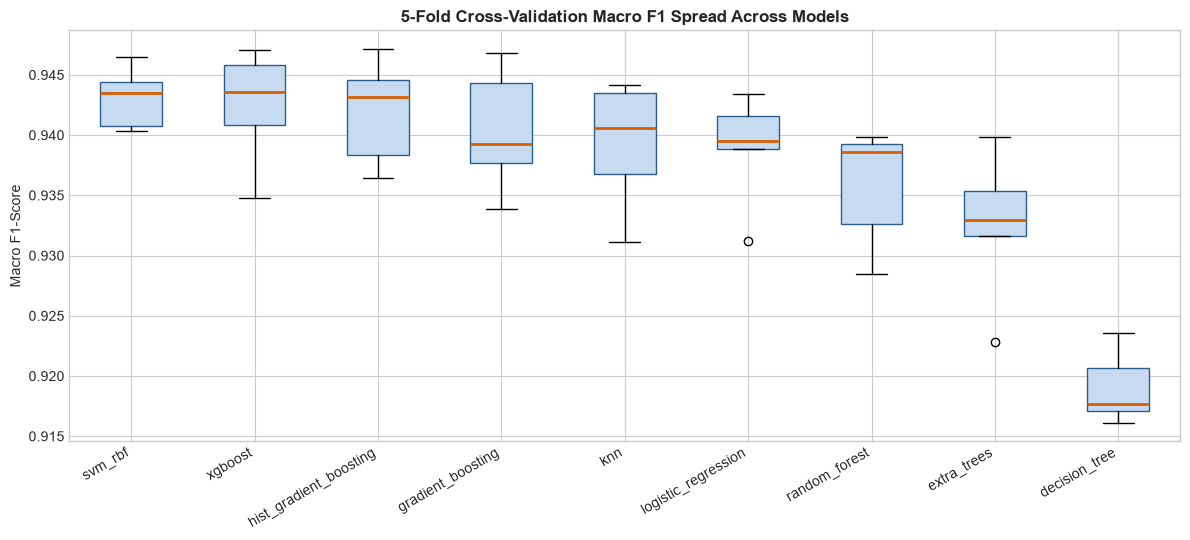

In [4]:
fig, ax = plt.subplots(figsize=(12, 5.5))
box_data = [raw_cv[m]['test_macro_f1'] for m in cv_summary_df['Model']]
ax.boxplot(box_data, patch_artist=True,
           boxprops=dict(facecolor='#c6dbef', color='#2b5c8f'),
           medianprops=dict(color='#d95f02', linewidth=2))
ax.set_xticks(range(1, len(cv_summary_df) + 1))
ax.set_xticklabels(cv_summary_df['Model'], rotation=30, ha='right')
ax.set_ylabel('Macro F1-Score')
ax.set_title('5-Fold Cross-Validation Macro F1 Spread Across Models', fontweight='bold')
plt.tight_layout()
plt.show()

In [5]:
param_grids = get_hyperparameter_grids()
candidate_pipes = {k: base_pipelines[k] for k in ['random_forest', 'svm_rbf', 'xgboost']}
tuned_models, tuning_df = tune_pipelines(
    candidate_pipes, param_grids, X_train, pd.Series(y_train), cv=5, random_state=42
)
display(tuning_df)

,Base Model,Tuned Model,Best CV Macro F1,Best Parameters,Tuning Search Time (s),Total Candidates Evaluated
0,svm_rbf,svm_rbf_tuned,0.9457,"{'classifier__C': 10.0, 'classifier__gamma': 0...",4.55,9
1,xgboost,xgboost_tuned,0.9439,"{'classifier__learning_rate': 0.05, 'classifie...",21.97,8
2,random_forest,random_forest_tuned,0.9367,"{'classifier__max_depth': 15, 'classifier__min...",25.31,12


In [6]:
all_models = {**base_pipelines, **tuned_models}
val_records = []
val_details = {}

for name, pipeline in all_models.items():
    res = evaluate_on_validation(
        pipeline, X_train, pd.Series(y_train), X_val, pd.Series(y_val), class_names=class_names
    )
    val_details[name] = res
    val_records.append({
        'Model': name,
        'Val Accuracy': res['accuracy'],
        'Val Macro F1': res['macro_f1'],
        'Val Weighted F1': res['weighted_f1'],
        'Val Macro Precision': res['macro_precision'],
        'Val Macro Recall': res['macro_recall'],
        'Training Time (s)': res['fit_time'],
        'Inference Time (s)': res['prediction_time'],
    })

val_summary_df = pd.DataFrame(val_records).sort_values('Val Macro F1', ascending=False).reset_index(drop=True)
val_summary_df['Rank'] = range(1, len(val_summary_df) + 1)
display(val_summary_df)

,Model,Val Accuracy,Val Macro F1,Val Weighted F1,Val Macro Precision,Val Macro Recall,Training Time (s),Inference Time (s),Rank
0,svm_rbf,0.9291,0.9389,0.9290,0.9392,0.9388,0.5137,0.3431,1
1,svm_rbf_tuned,0.9257,0.9369,0.9254,0.9375,0.9367,0.5341,0.3395,2
2,xgboost,0.9247,0.9359,0.9244,0.9356,0.9365,0.9526,0.0099,3
3,xgboost_tuned,0.9257,0.9358,0.9255,0.9363,0.9356,1.1714,0.0095,4
4,logistic_regression,0.9227,0.9314,0.9226,0.9318,0.9312,0.2048,0.0023,5
5,hist_gradient_boosting,0.9203,0.9313,0.9200,0.9318,0.9311,2.3187,0.0415,6
6,gradient_boosting,0.9178,0.9283,0.9176,0.9289,0.9279,82.0530,0.0255,7
7,random_forest_tuned,0.9173,0.9278,0.9169,0.9297,0.9266,0.4443,0.0407,8
8,random_forest,0.9168,0.9277,0.9164,0.9289,0.9269,0.7135,0.0787,9
9,knn,0.9149,0.9272,0.9146,0.9274,0.9271,0.0096,0.1440,10


Top Performing Architecture: svm_rbf
Validation Accuracy: 92.91%
Validation Macro F1: 0.9389


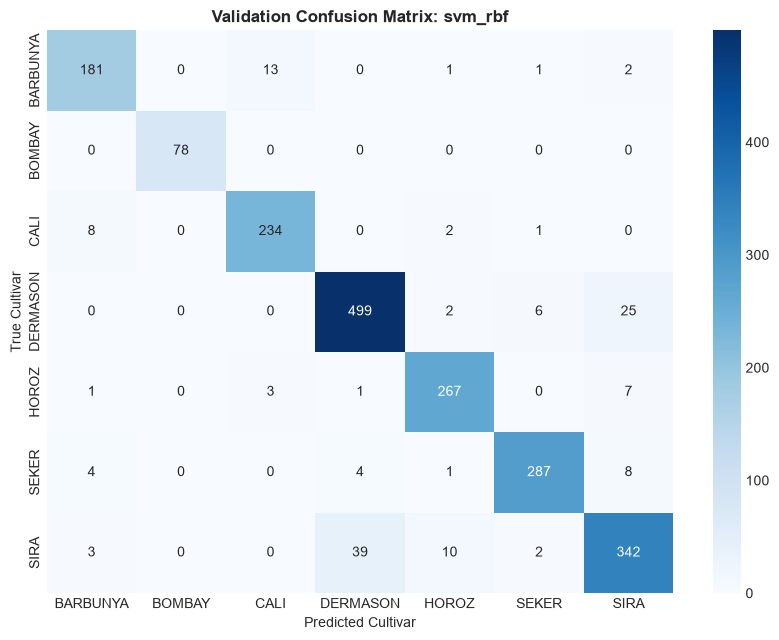

In [7]:
best_name = val_summary_df.iloc[0]['Model']
best_res = val_details[best_name]
print(f'Top Performing Architecture: {best_name}')
print(f'Validation Accuracy: {best_res["accuracy"]*100:.2f}%')
print(f'Validation Macro F1: {best_res["macro_f1"]:.4f}')

cm_labels = [class_names[i] for i in best_res['confusion_matrix_labels']]
cm_df = pd.DataFrame(best_res['confusion_matrix'], index=cm_labels, columns=cm_labels)

fig, ax = plt.subplots(figsize=(8.5, 6.5))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues', cbar=True, ax=ax)
ax.set_title(f'Validation Confusion Matrix: {best_name}', fontweight='bold')
ax.set_xlabel('Predicted Cultivar')
ax.set_ylabel('True Cultivar')
plt.tight_layout()
plt.show()

In [8]:
rep = best_res['classification_report']
per_class = []
for cls in class_names:
    if cls in rep:
        per_class.append({
            'Cultivar': cls,
            'Precision': round(rep[cls]['precision'], 4),
            'Recall': round(rep[cls]['recall'], 4),
            'F1-Score': round(rep[cls]['f1-score'], 4),
            'Support': int(rep[cls]['support']),
        })
display(pd.DataFrame(per_class))

,Cultivar,Precision,Recall,F1-Score,Support
0,BARBUNYA,0.9188,0.9141,0.9165,198
1,BOMBAY,1.0000,1.0000,1.0000,78
2,CALI,0.9360,0.9551,0.9455,245
3,DERMASON,0.9190,0.9380,0.9284,532
4,HOROZ,0.9435,0.9570,0.9502,279
5,SEKER,0.9663,0.9441,0.9551,304
6,SIRA,0.8906,0.8636,0.8769,396
